<a href="https://colab.research.google.com/github/raissabarb/cn/blob/main/Atividade_5_Raissa_Barbosa_Gauss_Seidel.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## Atividade Gauss-Seidel

Raissa Barbosa dos Santos

Exercício 1

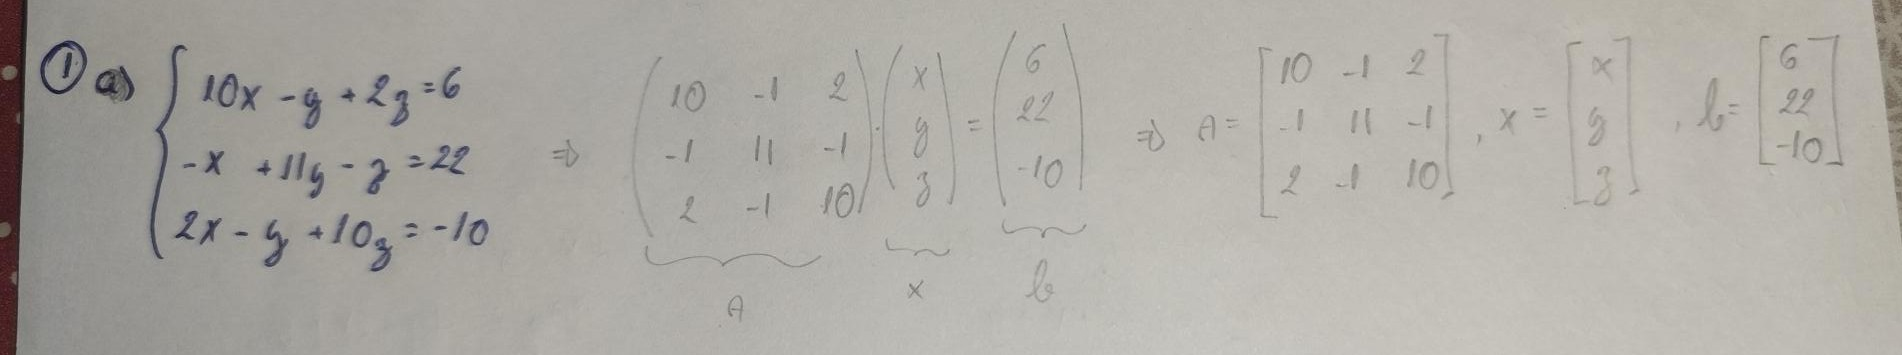

Exercício 2

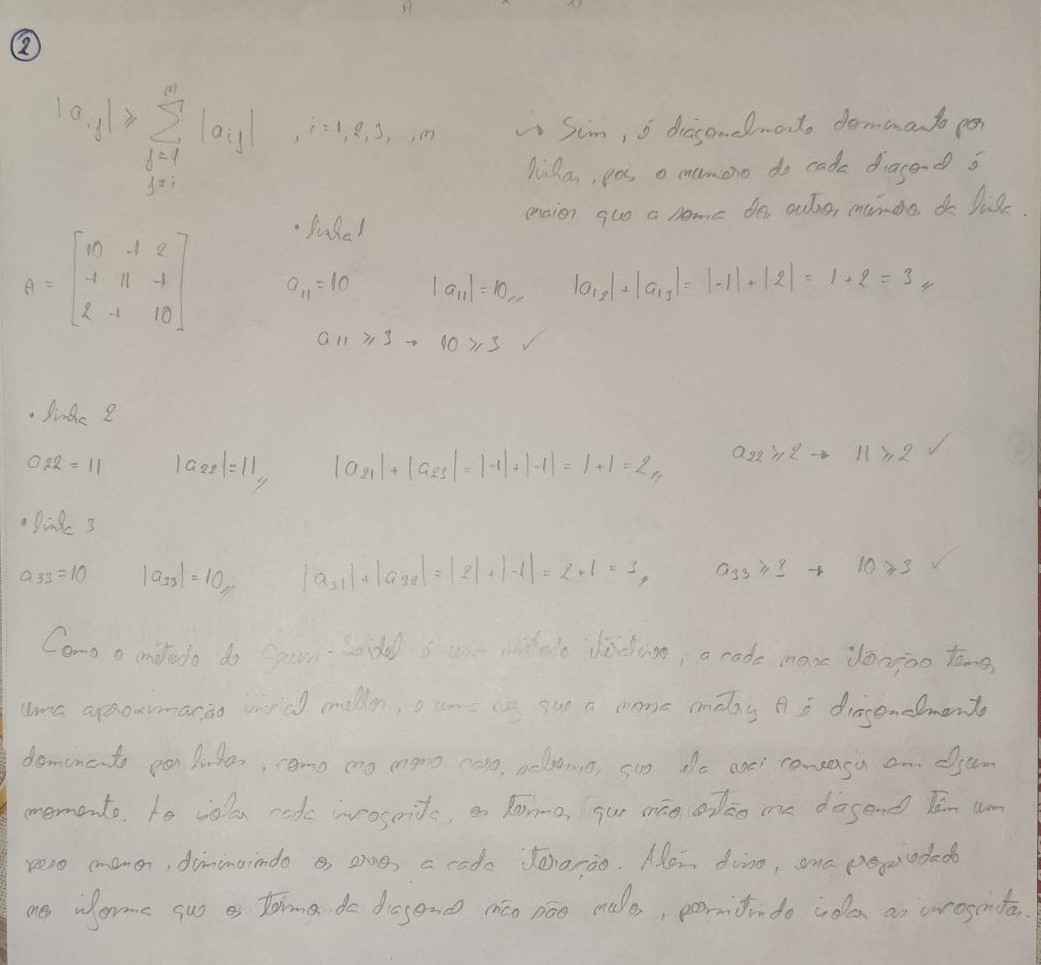

Exercício 3

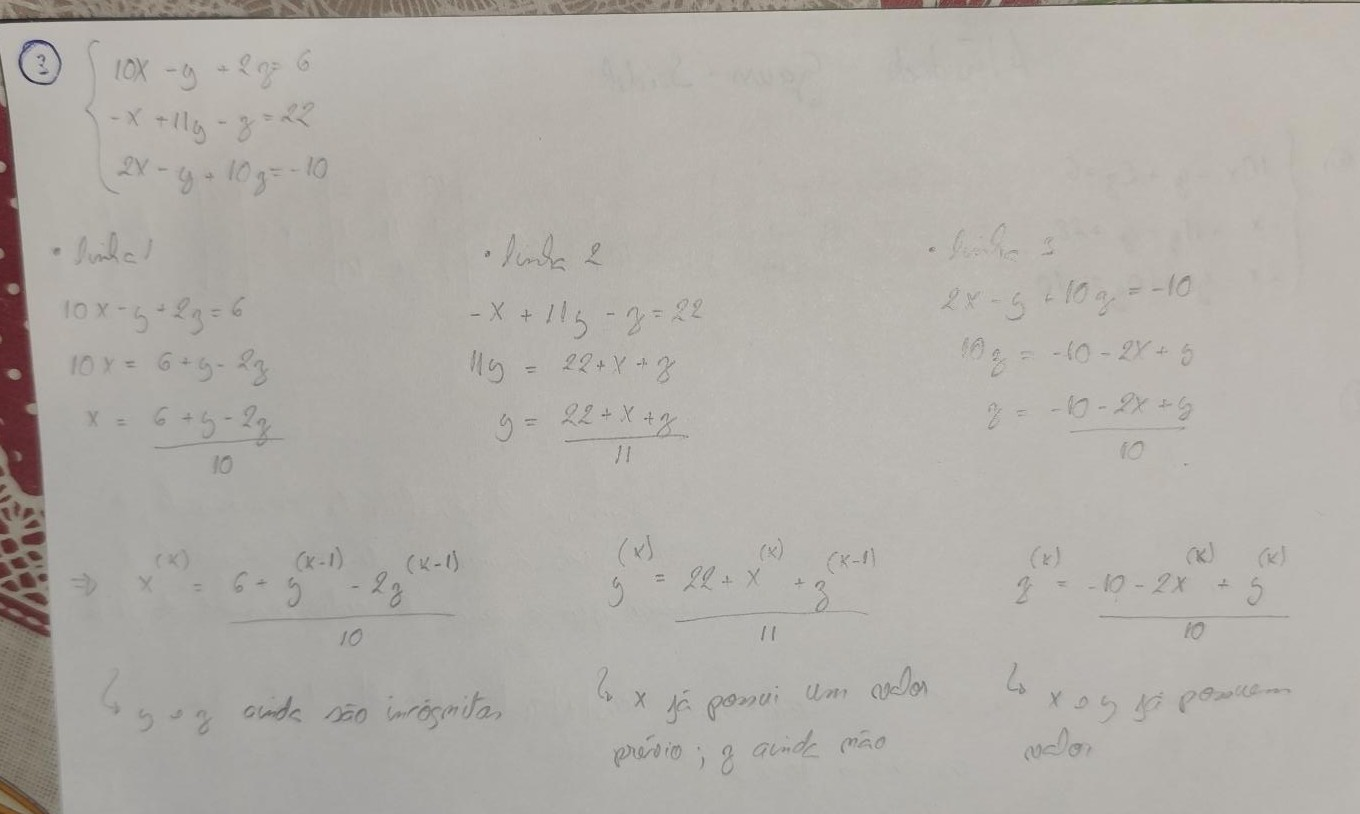

Exercício 4

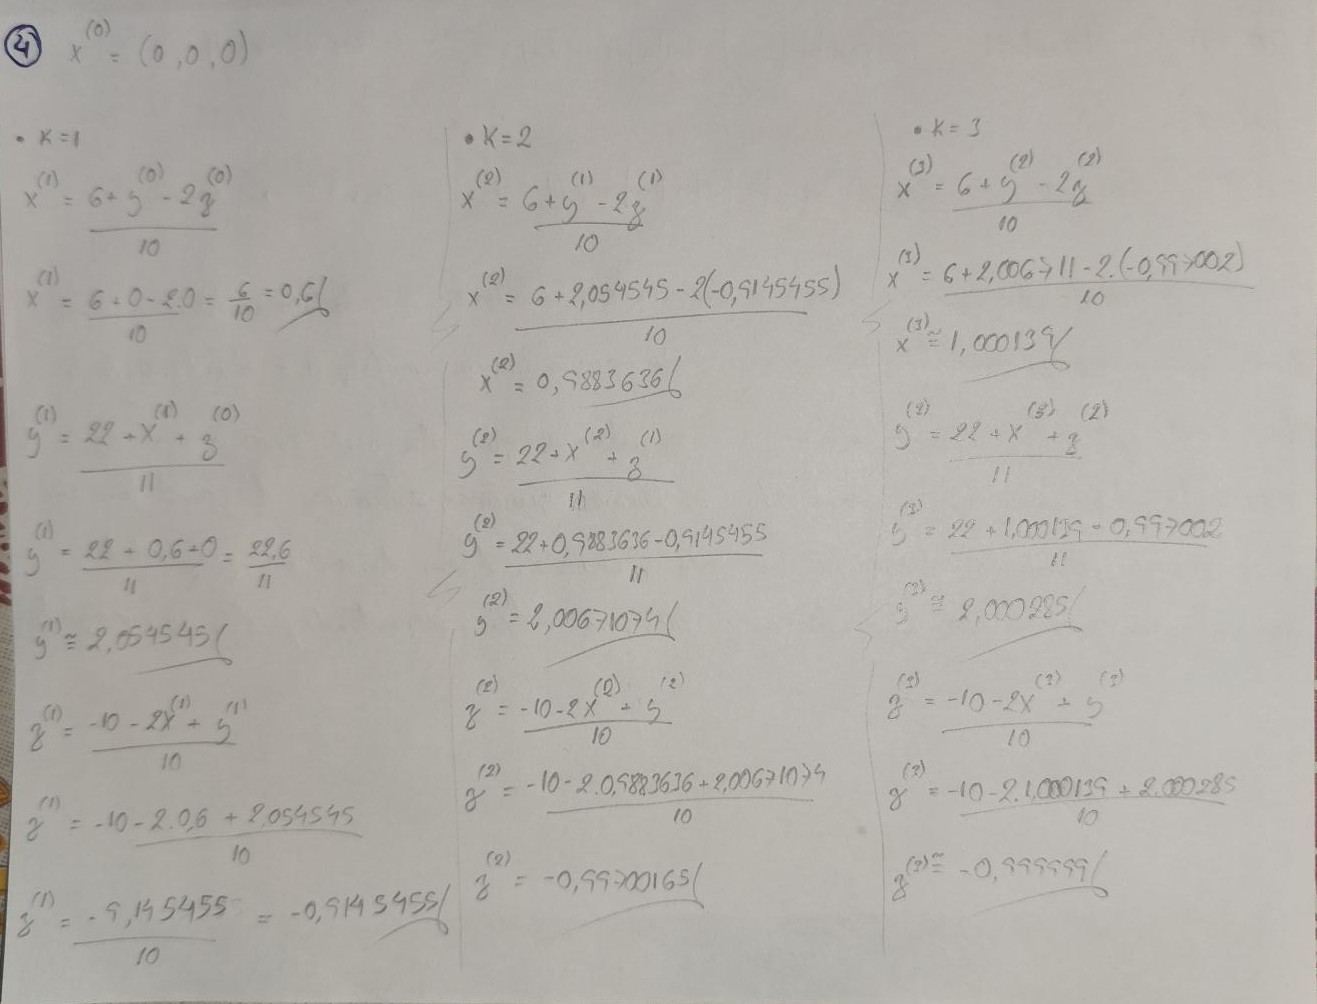

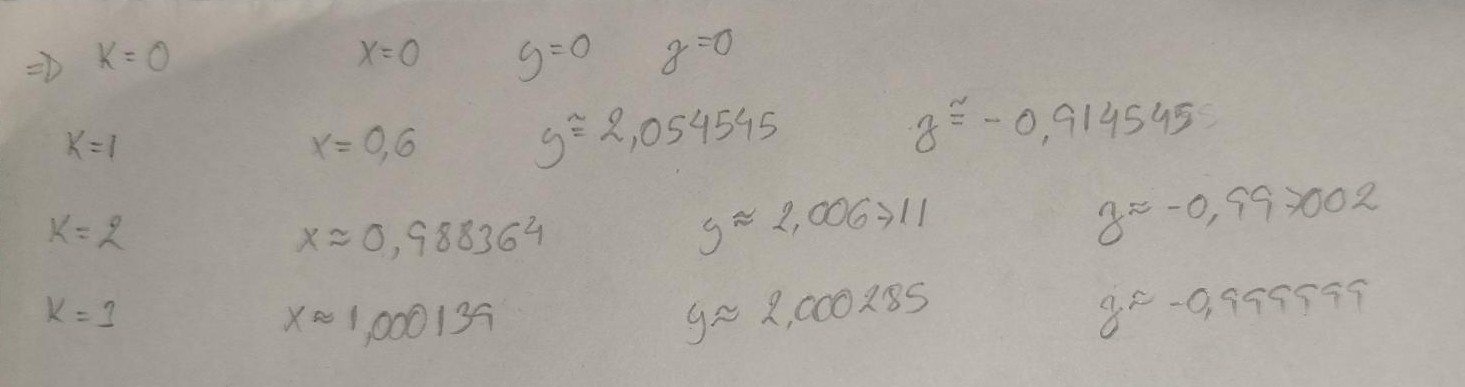

Exercício 5

In [4]:
import numpy as np
np.set_printoptions(precision=6, suppress=True)

# Sistema Ax = b
A = np.array([[10., -1.,  2.],
              [-1., 11., -1.],
              [ 2., -1., 10.]])

b = np.array([6., 22., -10.])

def gauss_seidel(A, b, x0, tol=1e-5, kmax=100):
    A = np.asarray(A, dtype=float)
    b = np.asarray(b, dtype=float)
    n = len(b)
    x = np.array(x0, dtype=float)

    historico = [(0, *x, np.nan)]

    for k in range(1, kmax + 1):
        x_antigo = x.copy()
        for i in range(n):
            soma = A[i, :i] @ x[:i] + A[i, i+1:] @ x[i+1:]
            x[i] = (b[i] - soma) / A[i, i]
        erro = np.max(np.abs(x - x_antigo))
        historico.append((k, *x, erro))
        if erro < tol:
            return x, k, historico
    return x, kmax, historico

# Execução com x^(0) = (0, 0, 0)
x_sol, iteracoes, hist = gauss_seidel(A, b, [0., 0., 0.])

print("Número de iterações:", iteracoes)
print("Solução aproximada (x, y, z):", x_sol)
print("Solução NumPy (conferência):", np.linalg.solve(A, b))
print("Resíduo b - Ax:", b - A @ x_sol)

Número de iterações: 6
Solução aproximada (x, y, z): [ 1.  2. -1.]
Solução NumPy (conferência): [ 1.  2. -1.]
Resíduo b - Ax: [-0.  0.  0.]


Exercício 6

In [5]:
import pandas as pd

tabela = pd.DataFrame(hist, columns=["k", "x(k)", "y(k)", "z(k)", "||x(k) - x(k-1)||_inf"])
tabela["k"] = tabela["k"].astype(int)

print(tabela.to_string(index=False, formatters={
    "x(k)": "{:.6f}".format,
    "y(k)": "{:.6f}".format,
    "z(k)": "{:.6f}".format,
    "||x(k) - x(k-1)||_inf": lambda v: "—" if pd.isna(v) else f"{v:.6e}"}))

 k     x(k)     y(k)      z(k) ||x(k) - x(k-1)||_inf
 0 0.000000 0.000000  0.000000                   NaN
 1 0.600000 2.054545 -0.914545          2.054545e+00
 2 0.988364 2.006711 -0.997002          3.883636e-01
 3 1.000071 2.000279 -0.999986          1.170777e-02
 4 1.000025 2.000004 -1.000005          2.755404e-04
 5 1.000001 2.000000 -1.000000          2.389216e-05
 6 1.000000 2.000000 -1.000000          1.262607e-06


Exercício 7

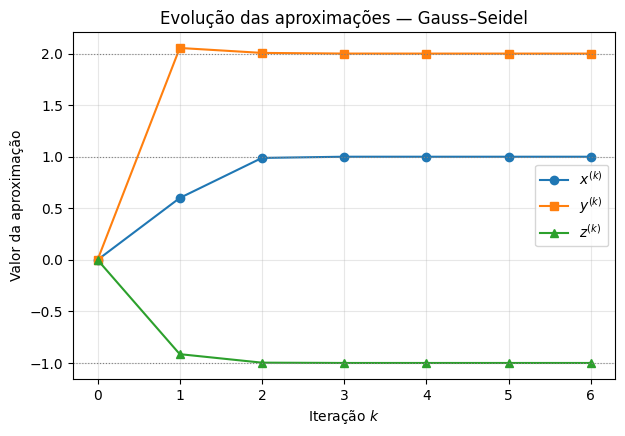

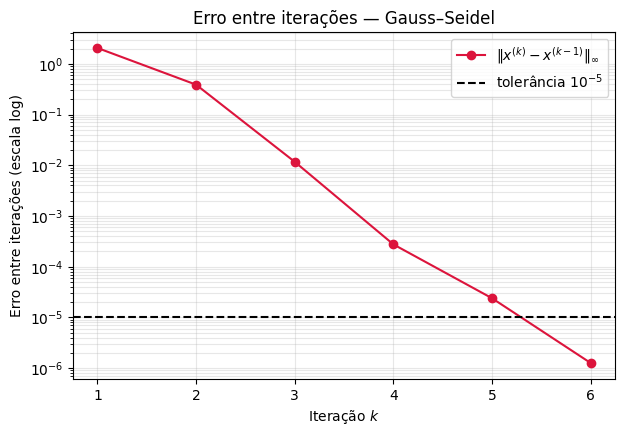

In [6]:
import matplotlib.pyplot as plt

k_vals = tabela["k"].to_numpy()
x_vals = tabela["x(k)"].to_numpy()
y_vals = tabela["y(k)"].to_numpy()
z_vals = tabela["z(k)"].to_numpy()
erros  = tabela["||x(k) - x(k-1)||_inf"].to_numpy()

# a
plt.figure(figsize=(7, 4.5))
plt.plot(k_vals, x_vals, "o-", label="$x^{(k)}$")
plt.plot(k_vals, y_vals, "s-", label="$y^{(k)}$")
plt.plot(k_vals, z_vals, "^-", label="$z^{(k)}$")

plt.axhline(1, color="gray", linestyle=":", linewidth=0.8)
plt.axhline(2, color="gray", linestyle=":", linewidth=0.8)
plt.axhline(-1, color="gray", linestyle=":", linewidth=0.8)

plt.xlabel("Iteração $k$")
plt.ylabel("Valor da aproximação")
plt.title("Evolução das aproximações — Gauss–Seidel")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

# b
plt.figure(figsize=(7, 4.5))
plt.semilogy(k_vals[1:], erros[1:], "o-", color="crimson",
             label=r"$\|x^{(k)}-x^{(k-1)}\|_\infty$")
plt.axhline(1e-5, color="black", linestyle="--", label="tolerância $10^{-5}$")

plt.xlabel("Iteração $k$")
plt.ylabel("Erro entre iterações (escala log)")
plt.title("Erro entre iterações — Gauss–Seidel")
plt.legend()
plt.grid(True, which="both", alpha=0.3)
plt.show()